# Feature Set Comparison for Baseline Dementia-Risk Classification
 
Compare two feature sets using the same train/test split and the same baseline classifiers:
1. MFCC summary features only.
2. MFCC summary features plus the additional acoustic features already available in the extracted feature CSV.


## 1. Imports and load the existing feature table

Run `baseline_ml_model.ipynb` first so `analysis_output/baseline_audio_features.csv` exists.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

RANDOM_STATE = 42
warnings.filterwarnings("ignore")

csv_candidates = [
    Path("analysis_output/baseline_audio_features.csv"),
    Path("../notebooks/analysis_output/baseline_audio_features.csv"),
    Path(r"D:\SKIT_Project\notebooks\analysis_output\baseline_audio_features.csv"),
]
csv_path = next((p.resolve() for p in csv_candidates if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError("baseline_audio_features.csv not found. Run the earlier baseline notebook first.")

data = pd.read_csv(csv_path)
print("Loaded:", csv_path)
print("Shape:", data.shape)
display(data.head())

Loaded: D:\SKIT_Project\notebooks\analysis_output\baseline_audio_features.csv
Shape: (360, 31)


,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,mfcc_5_mean,mfcc_5_std,...,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,duration_seconds,rms_mean,zcr_mean,path,label
0,-290.894226,90.324074,103.325874,40.952290,31.520834,27.468496,18.506176,24.015102,8.285114,17.901567,...,9.639206,3.368045,10.388342,-5.722221,11.232134,71.019688,0.042058,0.102158,D:\SKIT_Project\dataset\dementia\Abe Burrows\A...,dementia
1,-332.609802,80.299843,119.011658,42.997719,2.573827,32.044609,18.508610,22.891491,-3.082855,17.222090,...,10.582289,-9.440688,9.598793,5.068859,9.860040,47.000000,0.037931,0.104126,D:\SKIT_Project\dataset\dementia\Aileen Hernan...,dementia
2,-210.087753,119.215401,68.219551,46.933098,1.398461,29.873440,13.520696,24.507381,1.728840,19.050022,...,11.535592,-11.186091,11.773222,-5.553871,10.998050,38.000000,0.074112,0.142498,D:\SKIT_Project\dataset\dementia\Aileen Hernan...,dementia
3,-338.254486,84.265968,126.706917,42.934311,15.690623,33.033348,-8.187231,26.539669,10.898719,21.172417,...,10.341165,-9.548878,9.538286,-2.497692,8.797155,90.000000,0.031270,0.103313,D:\SKIT_Project\dataset\dementia\Aileen Hernan...,dementia
4,-361.912262,105.808426,96.568855,54.680119,2.274842,27.184465,36.884491,28.228430,4.056905,17.687374,...,13.294925,-4.440179,10.911772,-7.837333,10.456482,55.000000,0.018489,0.126244,D:\SKIT_Project\dataset\dementia\Alan Ramsey\a...,dementia


## 2. Define the feature sets

The CSV created by the earlier notebook contains 26 MFCC summary columns (13 means + 13 standard deviations), plus duration, RMS mean, and ZCR mean. This experiment compares MFCC-only against MFCC + those three additional acoustic features.

In [2]:
required = {"path", "label"}
if not required.issubset(data.columns):
    raise ValueError(f"Expected columns {required}; found {data.columns.tolist()}")

mfcc_cols = [c for c in data.columns if c.startswith("mfcc_")]
extra_acoustic_cols = [c for c in ["duration_seconds", "rms_mean", "zcr_mean"] if c in data.columns]

if len(mfcc_cols) == 0:
    raise ValueError("No MFCC columns found in the feature CSV.")
if not extra_acoustic_cols:
    raise ValueError("Expected duration_seconds, rms_mean, and/or zcr_mean columns were not found.")

feature_sets = {
    "MFCC only": mfcc_cols,
    "MFCC + extra acoustic": mfcc_cols + extra_acoustic_cols,
}
print("MFCC columns:", len(mfcc_cols))
print("Additional acoustic columns included:", extra_acoustic_cols)
print("Feature set sizes:", {name: len(cols) for name, cols in feature_sets.items()})
print("Class distribution:")
display(data["label"].value_counts().to_frame("count"))

MFCC columns: 26
Additional acoustic columns included: ['duration_seconds', 'rms_mean', 'zcr_mean']
Feature set sizes: {'MFCC only': 26, 'MFCC + extra acoustic': 29}
Class distribution:


,count
label,
nodementia,229
dementia,131


## 3. Create one fixed stratified train/test split

In [3]:
label_map = {"nodementia": 0, "dementia": 1}
y_all = data["label"].astype(str).str.strip().str.lower().map(label_map)
valid = y_all.notna()
data = data.loc[valid].reset_index(drop=True)
y = y_all.loc[valid].astype(int).reset_index(drop=True)

train_idx, test_idx = train_test_split(
    np.arange(len(data)),
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print("Train samples:", len(train_idx), "| Test samples:", len(test_idx))
print("Train labels:", y_train.value_counts().to_dict())
print("Test labels:", y_test.value_counts().to_dict())

Train samples: 270 | Test samples: 90
Train labels: {0: 172, 1: 98}
Test labels: {0: 57, 1: 33}


## 4. Compare models across feature sets

The same split is reused for each experiment so the comparison is more consistent. Preprocessing is fitted inside each pipeline using training data only. Because verified participant IDs have not yet been established, results are still preliminary and may be optimistic if the same participant has multiple recordings.

In [4]:
def build_models():
    return {
        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
        ]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE))
        ]),
        "SVM (RBF)": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", SVC(kernel="rbf", class_weight="balanced"))
        ]),
    }

rows = []
trained = {}
for feature_set_name, columns in feature_sets.items():
    X = data[columns].apply(pd.to_numeric, errors="coerce")
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    for model_name, model in build_models().items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        trained[(feature_set_name, model_name)] = model
        rows.append({
            "Feature Set": feature_set_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, pred),
            "Dementia Precision": precision_score(y_test, pred, pos_label=1, zero_division=0),
            "Dementia Recall": recall_score(y_test, pred, pos_label=1, zero_division=0),
            "Dementia F1-score": f1_score(y_test, pred, pos_label=1, zero_division=0),
        })

comparison_df = pd.DataFrame(rows).sort_values(
    ["Dementia F1-score", "Dementia Recall"], ascending=False
).reset_index(drop=True)
display(comparison_df.round(3))

,Feature Set,Model,Accuracy,Dementia Precision,Dementia Recall,Dementia F1-score
0,MFCC + extra acoustic,SVM (RBF),0.700,0.600,0.545,0.571
1,MFCC only,SVM (RBF),0.667,0.545,0.545,0.545
2,MFCC only,Logistic Regression,0.544,0.409,0.545,0.468
3,MFCC + extra acoustic,Logistic Regression,0.567,0.425,0.515,0.466
4,MFCC + extra acoustic,Random Forest,0.656,0.600,0.182,0.279
5,MFCC only,Random Forest,0.622,0.429,0.091,0.150


## 5. Visualize the comparison

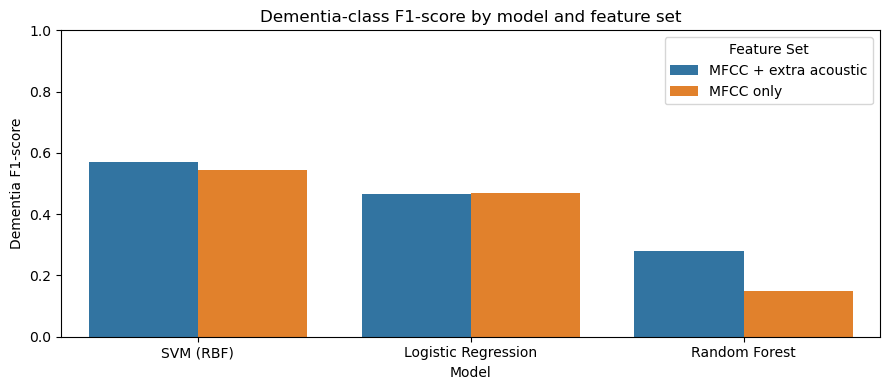

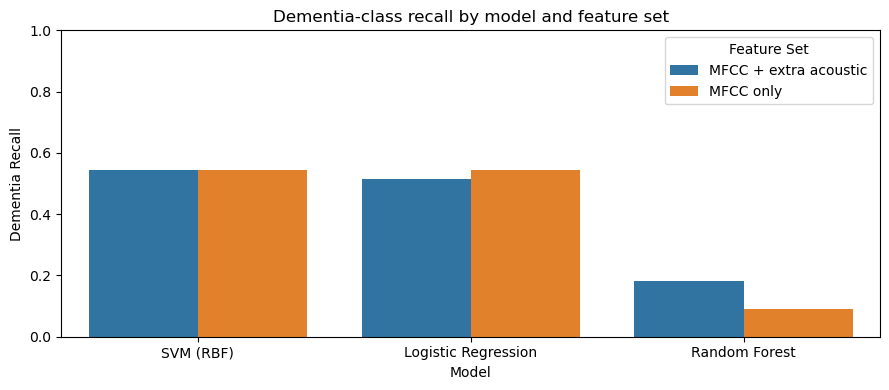

In [5]:
plt.figure(figsize=(9, 4))
sns.barplot(data=comparison_df, x="Model", y="Dementia F1-score", hue="Feature Set")
plt.ylim(0, 1)
plt.title("Dementia-class F1-score by model and feature set")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
sns.barplot(data=comparison_df, x="Model", y="Dementia Recall", hue="Feature Set")
plt.ylim(0, 1)
plt.title("Dementia-class recall by model and feature set")
plt.tight_layout()
plt.show()

## 6. Interpret the actual results

Use the table and plots above to answer:
- Did adding duration, RMS mean, and ZCR mean improve dementia-class F1-score?

  Adding the additional acoustic features improved the SVM model's dementia-class F1-score from 0.545 to 0.571. For Logistic Regression, the F1-score      slightly decreased from 0.468 to 0.466. Random Forest improved from 0.150 to 0.279, although its performance remained relatively weak for dementia       detection. Therefore, the additional features helped SVM and Random Forest in this experiment, but the improvement was not consistent across all         models.
  
- Which model-feature-set combination performed best on this split?

  SVM (RBF) with MFCC and additional acoustic features performed best on this test split. It achieved 70.0% accuracy, 0.600 dementia-class precision,      0.545 dementia-class recall, and a dementia-class F1-score of 0.571.

- Did a model have good overall accuracy but weak dementia recall?

  Yes. Random Forest with MFCC and additional acoustic features achieved 65.6% accuracy, but its dementia-class recall was only 0.182. It correctly        identified only 6 out of 33 dementia recordings. This shows that accuracy alone is not sufficient to evaluate dementia-risk classification.

- Are the differences large enough to justify further experiments?

  The results justify further experiments, but they do not establish that one feature set is consistently superior. The improvements were model-           dependent, and the dataset contains only 360 recordings. Further evaluation using appropriate validation methods, verification of participant            identities, and additional experiments is needed before selecting a final model.


## 7. Save the experiment results

In [6]:
output_dir = Path("analysis_output")
output_dir.mkdir(exist_ok=True)
output_file = output_dir / "feature_set_comparison.csv"
comparison_df.to_csv(output_file, index=False)
print("Saved comparison results to:", output_file.resolve())

Saved comparison results to: D:\SKIT_Project\notebooks\analysis_output\feature_set_comparison.csv
